# Sprint 3 · Semana 7: importancia de variables

Tesis: Detección Automatizada y Priorización de Eventos Adversos en Notas Clínicas mediante un Flujo de Procesamiento (Pipeline) de NLP y Aprendizaje Automático — Aplicación de la Matriz de Priorización del Modelo GEMSES sobre MIMIC-IV

Autor: Carlos Pérez Pérez · Curso: MIA-14 Trabajo de Investigación II · Docente: Dr. Glen Rodríguez · 28 de octubre de 2026

El presente cuaderno reúne el análisis de la importancia de variables del modelo vigente, el cual se entrega en la rama
`sprint3-importancia-variables` como parte del Sprint 3. El cuaderno no vuelve a entrenar el modelo, dado que el cálculo tomó
20.3 minutos, sino que lee los resultados que deja el *script* `src/importancia_variables.py` en la carpeta `reportes/` y a
partir de ellos construye cada tabla y cada figura. De esta manera, cada cifra del texto puede verificarse en las celdas de código, y no se
requiere acceso a los datos de MIMIC-IV, protegidos por el acuerdo de uso de PhysioNet.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
import figuras_imp  # mismas funciones que dibujan reportes/figuras/fig_imp_*.png

leer = lambda n: json.loads((RAIZ / "reportes" / n).read_text(encoding="utf-8"))
R, Hp = leer("importancia_resultados.json"), leer("hp_resultados.json")
G = pd.read_csv(RAIZ / "reportes" / "importancia_grupos.csv")
T = pd.read_csv(RAIZ / "reportes" / "importancia_terminos.csv", keep_default_na=False)
plt.rcParams.update({"font.size": 9})
print("Resultados leídos:", R["generado"], "· semilla", R["semilla"], "· modelo", R["modelo"], "con", R["variante"])

Resultados leídos: 2026-10-28T11:51:50 · semilla 42 · modelo A+B+C con D2


## 1. Punto de partida: el modelo vigente

En la búsqueda de hiperparámetros de esta misma semana, la regla fijada antes de correr mantuvo la configuración actual, cuya PR-AUC (área
bajo la curva de precisión y sensibilidad) fue 0.8534 ± 0.0041 en la validación cruzada de 5 *folds*. Por
consiguiente, el modelo que se analiza es D2 con A+B+C, es decir, palabras (A) y bigramas (B) de la epicrisis con 20 000 términos cada uno y
`min_df` de 3, y variables de la hospitalización con el largo de la nota (C). La regresión logística usa C de 1, clases balanceadas y la
frecuencia sublineal de `src/features.py`.

In [2]:
print("Decisión de la búsqueda de hiperparámetros:", Hp["decision"])
print("PR-AUC de la configuración actual (5 folds):", round(Hp["confirmacion_5_folds"]["actual"]["pr_auc_media"], 4), "±",
      round(Hp["confirmacion_5_folds"]["actual"]["pr_auc_std"], 4))
print("Configuración analizada:", R["configuracion"])

Decisión de la búsqueda de hiperparámetros: se mantiene la configuración actual
PR-AUC de la configuración actual (5 folds): 0.8534 ± 0.0041
Configuración analizada: {'C': 1.0, 'A_max_features': 20000, 'A_min_df': 3, 'B_max_features': 20000, 'B_min_df': 3, 'class_weight': 'balanced', 'sublinear_tf': True}


Fuente: elaboración propia a partir de `reportes/hp_resultados.json` y `reportes/importancia_resultados.json`.

## 2. Diseño del análisis, fijado antes de ver los resultados

La importancia de una variable (cuánto depende el modelo ya entrenado de ella para separar las epicrisis con evento de las que no lo tienen)
se midió de tres maneras complementarias, las cuales resume el Cuadro 1. Los parámetros están en `config/config.yaml` (sección
`importancia`). En el equipo donde se corrió, ese archivo se modificó por última vez a las 11:17 del 28 de octubre de 2026 y el *script* a las
11:31:21, antes de que empezara la corrida, a las 11:31:31. La única prueba de ese orden son las horas de modificación de los archivos, dado
que no hay un *commit* anterior a la corrida.

Cuadro 1. Métodos de importancia

| Método | Qué mide | Cómo se calcula |
|---|---|---|
| Permutación por bloque | cuánto depende el modelo de cada bloque (A, B y C) | se permutan juntas, entre las epicrisis de validación del *fold*, todas las columnas del bloque, 30 veces, y se mide la caída de la PR-AUC |
| Permutación dentro de C | cuánto depende el modelo de cada variable de contexto | lo mismo, por variable original; las columnas *one-hot* y la marca de faltante de una variable se permutan juntas |
| Coeficientes de la regresión | qué términos de A y de B empujan hacia evento o hacia sin evento | los 20 términos de mayor coeficiente positivo y negativo de cada *fold* (el *top*), y su estabilidad entre los 5 *folds* |

Fuente: elaboración propia a partir de `config/config.yaml` y `src/importancia_variables.py`.

La importancia se calculó solo con los 5 *folds* del proyecto (partes en que se divide el conjunto de *train* para entrenar con cuatro y
evaluar con la que queda), separados por paciente y con semilla 42. En cada *fold*, el modelo se entrena con las filas de D2 y se evalúa en las
epicrisis de validación sin etiqueta dudosa, igual que en las semanas 6 y 7. No se usó la partición de *test*, con el fin de no gastarla y de
no anticipar la hipótesis específica HE1.

Asimismo, no se calculó ninguna importancia ni ningún desempeño por servicio, grupo de edad o largo de la nota, dado que esa comparación es la
de HE1 y se reserva para otro momento. Como el modelo es lineal, permutar las filas de un grupo de columnas equivale a permutar su aporte al
*logit*, por lo cual cada permutación no exige volver a transformar el texto.

Antes de mostrar o guardar cualquier término se aplicó el filtro de privacidad del Cuadro 2, exigido por la licencia de PhysioNet. El filtro se
aplicó a los 50 términos de mayor coeficiente de cada signo, bloque y *fold*, y solo los que lo pasan llegan a
`reportes/importancia_terminos.csv` y a las figuras.

Cuadro 2. Filtro de privacidad de los términos

| Criterio | Regla | Origen |
|---|---|---|
| Solo letras | cada palabra del término tiene solo letras a-z, sin dígitos ni el marcador de anonimización ___ | criterio del autor |
| Pacientes | el término aparece en las epicrisis de al menos 100 pacientes distintos de *train* | criterio del autor |
| Epicrisis | el término aparece en al menos el 1% de las epicrisis de *train* (560 de 55 915) | precedente del EDA de la semana 4: `src/eda_texto.py`, línea 21 (`MIN_DF = 0.01`), con el que se publicaron términos de esa frecuencia mínima |
| Nombre propio | ninguna palabra del término va con mayúscula inicial en más del 50% de sus apariciones, en una muestra de 10 000 epicrisis de *train* | criterio del autor (heurístico) |

Fuente: elaboración propia a partir de `config/config.yaml` y `src/eda_texto.py`.

Es preciso tomar en consideración tres límites de interpretación. En primer lugar, la importancia no es causalidad, dado que mide cuánto
depende el modelo de una variable y no si esa variable produce el evento. En segundo lugar, los coeficientes de TF-IDF dependen de la escala de
cada término y de su correlación con los demás, por lo cual se leen como asociación del modelo y no como efecto de la palabra. En tercer lugar,
a criterio del autor, si dos bloques comparten información, la permutación de uno solo puede subestimar su importancia, porque el bloque que
no se permuta conserva parte de esa información.

Por último, los resultados se comparan con la ablación de la semana 5 y con la permutación de la semana 6, que se leen de
`reportes/fe_resultados.json` y `reportes/datos_resultados.json` sin recalcularlas. La lectura clínica de los términos, cuando se hace, va
rotulada como interpretación del autor y no como hallazgo.

In [3]:
print("Partición:", R["particion"])
print("Parámetros:", R["parametros"])
print("Mínimo de epicrisis del filtro:", R["filtro_privacidad"]["min_notas"], "de", R["n_train"], "epicrisis de train",
      f"({R['parametros']['filtro_privacidad']['min_pct_notas']:g}%)")
for f in sorted((RAIZ / "logs").glob("importancia_variables_*.log")):
    print(f.name, "· inicio:", f.read_text(encoding="utf-8").splitlines()[0][:19])

Partición: StratifiedGroupKFold(5, shuffle=True, random_state=42) por subject_id en train; entrenan las filas de D2; se evalúa en las epicrisis de validación sin etiqueta dudosa; no se usa test
Parámetros: {'particion': 'confirmacion', 'n_repeticiones': 30, 'top_terminos': 20, 'candidatos_por_fold': 50, 'mostrar_terminos': 15, 'filtro_privacidad': {'min_pacientes': 100, 'min_pct_notas': 1.0, 'solo_letras': True, 'max_pct_mayuscula_inicial': 50, 'muestra_mayusculas': 10000}}
Mínimo de epicrisis del filtro: 560 de 55915 epicrisis de train (1%)
importancia_variables_20261028_113131.log · inicio: 2026-10-28 11:31:31
importancia_variables_prueba_20261028_123034.log · inicio: 2026-10-28 12:30:34


## 3. Control de reproducción y de la caché

El *script* reutiliza los conteos de palabras y bigramas que dejó la búsqueda de hiperparámetros en `data/interim/cache_hp/`. Para comprobar que
esa caché es equivalente, en cada *fold* se ajustaron además los bloques del *pipeline* de `src/features.py` sobre las mismas filas, y las
15 comparaciones (5 *folds* por 3 bloques) dieron matrices idénticas. Asimismo, como se aprecia en la Tabla 1, la PR-AUC de
validación de cada *fold* reproduce la de D2 registrada en la semana 6, con una diferencia máxima de 0.000000.

In [4]:
c = R["control_reproduccion"]
t1 = pd.DataFrame({"semana 6 (D2)": c["pr_auc_semana6"], "esta corrida": c["pr_auc_base_esta_corrida"]},
                  index=pd.Index(range(1, 6), name="Tabla 1. PR-AUC de validación por fold"))
display(t1)
eq = R["equivalencia_cache_pipeline"]
print("Comparaciones caché frente al pipeline:", len(eq["detalle"]), "· todas iguales:", eq["todos_iguales"], "· reproduce la semana 6:", c["reproduce"])

,semana 6 (D2),esta corrida
Tabla 1. PR-AUC de validación por fold,,
1,0.856697,0.856697
2,0.852738,0.852738
3,0.846717,0.846717
4,0.854189,0.854189
5,0.856627,0.856627


Comparaciones caché frente al pipeline: 15 · todas iguales: True · reproduce la semana 6: True


Fuente: elaboración propia a partir de `reportes/importancia_resultados.json` y `reportes/datos_folds.csv`.

El *script* tiene, además, un modo de prueba (`--prueba`) que corre 2 *folds* con 2 permutaciones y escribe sus salidas fuera de git, en
`data/interim/prueba_imp/`; su registro se conserva en `logs/`. Una primera corrida de prueba falló al final por un choque de nombres de
variable en el *script*, el cual se corrigió antes de la corrida completa, y su registro no se conservó. La celda siguiente muestra los
controles del registro de prueba que se conserva.

In [5]:
prueba = sorted((RAIZ / "logs").glob("importancia_variables_prueba_*.log"))[-1]
for l in prueba.read_text(encoding="utf-8").splitlines():
    if "caché igual" in l or "control:" in l or "Salidas" in l:
        print(l.split(" | ")[0][11:], "·", l.split(" | ")[-1][:150])

12:34:28 · fold 1: caché igual al pipeline de features.py en A, B y C: True
12:38:14 · fold 2: caché igual al pipeline de features.py en A, B y C: True
12:41:50 · control: la PR-AUC de cada fold reproduce la semana 6: {'pr_auc_base_esta_corrida': [0.856697, 0.852738], 'pr_auc_semana6': [0.856697, 0.852738], 'dif
12:41:52 · Salidas: data/interim/prueba_imp/metrics_importancia.txt · data/interim/prueba_imp/importancia_resultados.json · data/interim/prueba_imp/importancia_g


## 4. Importancia por bloque

La Tabla 2 presenta la caída de la PR-AUC al permutar cada bloque, como media de los 5 *folds*, con su desviación estándar entre *folds*, el
valor de cada *fold* y la desviación media entre las 30 permutaciones de un mismo *fold*.

In [6]:
t2 = pd.DataFrame({k: {"caída media": v["media"], "desviación entre folds": v["std"], "desviación entre permutaciones": v["std_repeticiones_media"],
                       "columnas (media)": round(G[G.grupo == k].n_columnas.mean(), 1), "por fold": [round(x, 4) for x in v["por_fold"]]}
                   for k, v in R["importancia_bloques"].items()}).T
t2.index.name = "Tabla 2. Bloque"
display(t2)
b = G[G.tipo == "bloque"].pivot(index="fold", columns="grupo", values="caida_media")[["A · palabras", "B · bigramas", "C · contexto"]]
print("Suma de las caídas de A y B por separado:", round(R["importancia_bloques"]["A · palabras"]["media"] + R["importancia_bloques"]["B · bigramas"]["media"], 4),
      "· caída de A+B juntos:", R["importancia_bloques"]["A+B · texto completo"]["media"])
print("Orden de los bloques en cada fold:", [" > ".join(r.sort_values(ascending=False).index.str[0]) for _, r in b.iterrows()])

,caída media,desviación entre folds,desviación entre permutaciones,columnas (media),por fold
Tabla 2. Bloque,,,,,
A · palabras,0.12742,0.00276,0.00438,20000.0,"[0.128, 0.1286, 0.1231, 0.1306, 0.1268]"
B · bigramas,0.03309,0.00132,0.002273,20000.0,"[0.0336, 0.031, 0.0332, 0.0346, 0.033]"
C · contexto,0.11063,0.00342,0.003933,91.2,"[0.1106, 0.1148, 0.1075, 0.107, 0.1133]"
A+B · texto completo,0.23492,0.00459,0.005745,40000.0,"[0.2349, 0.2334, 0.2303, 0.2426, 0.2333]"


Suma de las caídas de A y B por separado: 0.1605 · caída de A+B juntos: 0.23492
Orden de los bloques en cada fold: ['A > C > B', 'A > C > B', 'A > C > B', 'A > C > B', 'A > C > B']


Fuente: elaboración propia a partir de `reportes/importancia_resultados.json` y `reportes/importancia_grupos.csv`.

Como se aprecia en la Tabla 2, el bloque de mayor peso es el de las palabras (A), cuya permutación reduce la PR-AUC en 0.1274 ±
0.0028, seguido del contexto (C), con 0.1106 ± 0.0034, y de los bigramas (B), con 0.0331 ±
0.0013. La desviación entre *folds* es pequeña frente a cada caída, de modo que el orden de los tres bloques no depende de cómo se
partieron los datos.

Por otra parte, al permutar juntas las palabras y los bigramas la caída es 0.2349, mayor que la suma de las dos por separado
(0.1605). A criterio del autor, que la caída conjunta supere a la suma es coherente con que ambos bloques compartan
información, aunque no lo demuestra, dado que la caída de la PR-AUC no tiene por qué ser aditiva.

Figura 1. Importancia por bloque y comparación con las semanas 5 y 6

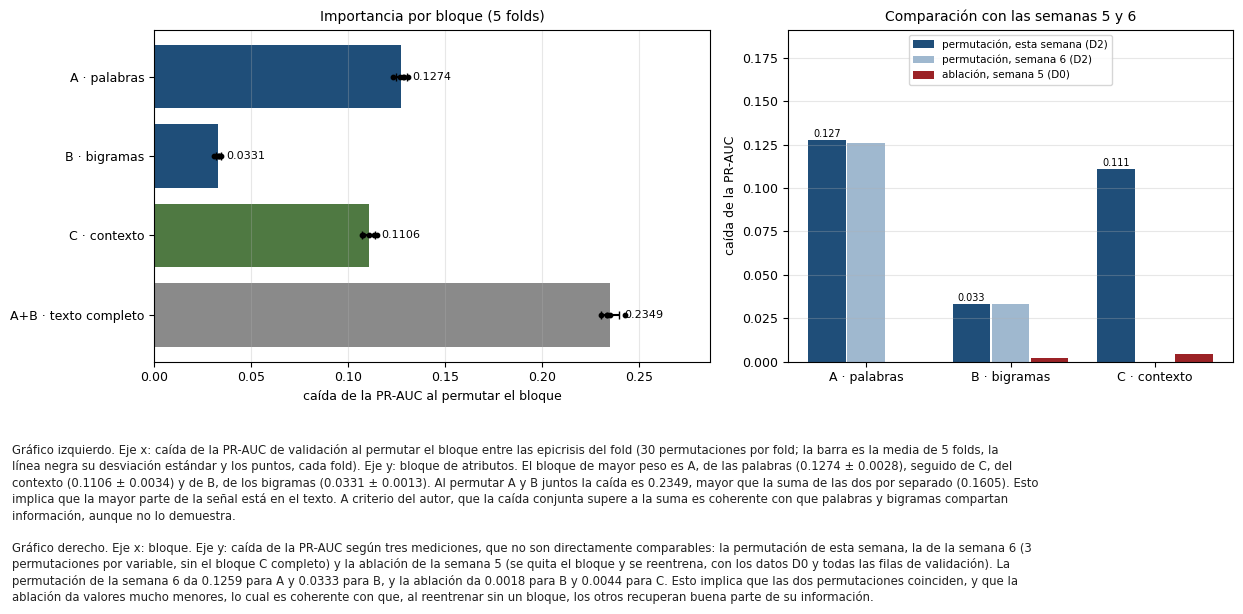

In [7]:
fig = figuras_imp.fig_bloques(R)
plt.show()

Fuente: elaboración propia a partir de `reportes/importancia_resultados.json`, `reportes/fe_resultados.json` y
`reportes/datos_resultados.json`.

En el gráfico derecho de la Figura 1 se observa que la permutación de esta semana coincide con la de la semana 6 en las palabras
(0.1274 frente a 0.1259) y en los bigramas (0.0331 frente a 0.0333).
La semana 6, sin embargo, usó 3 permutaciones por variable y no calculó el bloque C completo. Por el contrario, la ablación de la semana 5, que quita
el bloque y vuelve a entrenar, da caídas mucho menores, de 0.0018 para B y de 0.0044 para C.

In [8]:
cmp = R["comparacion"]
t3 = pd.DataFrame({"permutación, esta semana (D2)": {k[0]: v["media"] for k, v in R["importancia_bloques"].items() if k[0] in "ABC" and "+" not in k},
                   "permutación, semana 6 (D2)": {"A": cmp["permutacion_semana6"]["A"], "B": cmp["permutacion_semana6"]["B"], "C": None},
                   "ablación, semana 5 (D0)": {"A": None, "B": cmp["ablacion_semana5"]["B"], "C": cmp["ablacion_semana5"]["C"]}})
t3.index.name = "Tabla 3. Bloque"
display(t3)
print("Ablación de la semana 5 (PR-AUC en validación cruzada):", {k: cmp["ablacion_semana5"][k] for k in ("A+B+C", "A+C", "A+B")},
      "· contexto sin texto:", cmp["ablacion_semana5"]["C_sin_texto"])

,"permutación, esta semana (D2)","permutación, semana 6 (D2)","ablación, semana 5 (D0)"
Tabla 3. Bloque,,,
A,0.12742,0.1259,NaN
B,0.03309,0.0333,0.0018
C,0.11063,NaN,0.0044


Ablación de la semana 5 (PR-AUC en validación cruzada): {'A+B+C': 0.8732, 'A+C': 0.8714, 'A+B': 0.8688} · contexto sin texto: 0.7771


Fuente: elaboración propia a partir de `reportes/importancia_resultados.json`, `reportes/fe_resultados.json` y
`reportes/datos_resultados.json`.

Como se aprecia en la Tabla 3, las dos mediciones responden a preguntas distintas. La permutación mide cuánto se apoya el modelo ya entrenado
en un bloque, mientras que la ablación mide cuánto pierde un modelo que se entrena sin ese bloque y que, por ello, puede recuperar parte de la
información en los bloques que quedan. A criterio del autor, la distancia entre ambas, sobre todo en el contexto (0.1106 frente a
0.0044), indica que el modelo usa el contexto, pero que el texto contiene casi toda esa información. Es preciso
tomar en consideración, además, que la ablación se midió con los datos D0 y todas las filas de validación, y no con D2.

## 5. Importancia de las variables de contexto

La Tabla 4 presenta la caída de la PR-AUC al permutar cada una de las 19 variables del bloque C, ordenadas de mayor a menor, junto con
el valor de la permutación de la semana 6.

In [9]:
s6 = R["comparacion"]["permutacion_semana6"]["variables_de_C"]
t4 = pd.DataFrame({figuras_imp.NOMBRE.get(k, k): {"caída media": v["media"], "desviación entre folds": v["std"],
                                                  "columnas (media)": round(G[G.grupo == k].n_columnas.mean(), 1),
                                                  "semana 6": s6.get(k)} for k, v in R["importancia_contexto"].items()}).T
t4.index.name = "Tabla 4. Variable de contexto"
display(t4)
print("Suma de las caídas por variable:", round(sum(v["media"] for v in R["importancia_contexto"].values()), 4),
      "· bloque C completo:", R["importancia_bloques"]["C · contexto"]["media"],
      "· variables por debajo de 0.0005:", sum(v["media"] < 0.0005 for v in R["importancia_contexto"].values()))

,caída media,desviación entre folds,columnas (media),semana 6
Tabla 4. Variable de contexto,,,,
estancia (días),0.01319,0.00139,2.0,0.0136
servicio al ingreso,0.00613,0.00112,18.0,0.0061
largo de la nota,0.00539,0.00022,2.0,0.0053
servicio al alta,0.00403,0.00083,17.8,0.0044
n.º de cultivos,0.00383,0.00081,1.0,0.0037
destino al alta,0.00369,0.00091,13.4,0.0038
n.º de medicamentos,0.00130,0.00042,1.0,0.0012
tipo de ingreso,0.00081,0.00036,9.0,0.0008
procedencia,0.00076,0.00026,10.0,0.0007


Suma de las caídas por variable: 0.0401 · bloque C completo: 0.11063 · variables por debajo de 0.0005: 10


Fuente: elaboración propia a partir de `reportes/importancia_resultados.json` y `reportes/datos_resultados.json`.

Como se aprecia en la Tabla 4, las tres variables de contexto de mayor peso son estancia (días) (0.0132),
servicio al ingreso (0.0061) y largo de la nota (0.0054), mientras que
10 de las 19 variables quedan por debajo de 0.0005. Asimismo, los valores son muy cercanos a los de la semana 6, que usó el
mismo modelo y los mismos *folds* con menos permutaciones.

Figura 2. Importancia de las variables de contexto

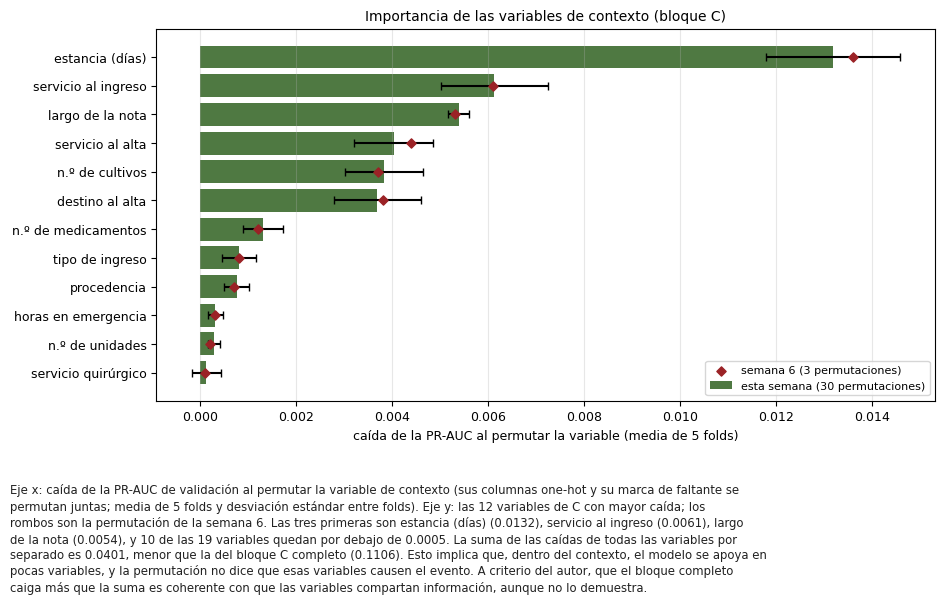

In [10]:
fig = figuras_imp.fig_contexto(R)
plt.show()

Fuente: elaboración propia a partir de `reportes/importancia_resultados.json`.

En la Figura 2 se observa, además, que la suma de las caídas de todas las variables por separado (0.0401) es menor que la caída del
bloque C completo (0.1106). A criterio del autor, esto es coherente con que las variables de contexto también compartan
información entre sí, aunque no lo demuestra. Asimismo, el peso de la estancia y del servicio refuerza la
duda, planteada desde la semana 5, de si el modelo reconoce en parte el tipo de paciente; esa duda corresponde a HE1 y no se resuelve aquí.

## 6. Coeficientes de los términos y su estabilidad entre *folds*

La Tabla 5 presenta la estabilidad de los términos de mayor coeficiente entre los 5 *folds*, medida sin mostrar ningún término. Se informan la
correlación de rangos de Spearman de todos los coeficientes entre cada par de *folds* y el número de términos que están en el *top*
20 de los 5 *folds*. También se informa el índice de Jaccard medio entre los *top* de cada par de *folds*, que vale 1 si los dos
*top* son iguales y 0 si no comparten ningún término.

In [11]:
filas = {}
for blq, e in R["estabilidad_coeficientes"].items():
    for signo in ("positivo", "negativo"):
        filas[f"{blq} · {signo}"] = {"Spearman medio (todos los términos)": e["spearman_coeficientes"]["media"],
                                     f"en el top {e[signo]['top']} de los 5 folds": e[signo]["en_los_5_folds"],
                                     "en al menos 3 folds": e[signo]["en_al_menos_3_folds"],
                                     "términos distintos en los 5 top": e[signo]["terminos_distintos_en_los_top"],
                                     "Jaccard medio": e[signo]["jaccard_medio_entre_pares"]}
t5 = pd.DataFrame(filas).T
t5.index.name = "Tabla 5. Bloque y signo del coeficiente"
t5

,Spearman medio (todos los términos),en el top 20 de los 5 folds,en al menos 3 folds,términos distintos en los 5 top,Jaccard medio
Tabla 5. Bloque y signo del coeficiente,,,,,
A · positivo,0.7769,15.0,21.0,25.0,0.7813
A · negativo,0.7769,3.0,12.0,55.0,0.2548
B · positivo,0.7696,16.0,19.0,27.0,0.7880
B · negativo,0.7696,2.0,10.0,59.0,0.2109


Fuente: elaboración propia a partir de `reportes/importancia_resultados.json`.

Como se aprecia en la Tabla 5, la correlación de rangos de los coeficientes entre *folds* es de 0.78 en
las palabras y de 0.77 en los bigramas. De los 20 términos de mayor coeficiente
positivo, 15 palabras y 16 bigramas se repiten en los 5 *folds*, con un Jaccard
medio de 0.78 y 0.79. En cambio, del lado negativo
solo se repiten 3 y 2, con un Jaccard de
0.25 y 0.21. De esta manera, los términos que empujan
hacia evento son estables, mientras que los que empujan hacia sin evento cambian de un *fold* a otro.

La Tabla 6 presenta el resultado del filtro de privacidad sobre los términos candidatos. Un término puede incumplir más de un criterio, por lo
cual la suma por criterio puede superar al total de excluidos.

In [12]:
fp = R["filtro_privacidad"]
t6 = pd.Series({"términos candidatos": fp["candidatos"], **{f"incumple: {k.replace(' %', '%')}": v for k, v in fp["por_motivo"].items()},
                "excluidos (al menos un criterio)": fp["excluidos"], "publicables": fp["publicables"]}, name="términos").to_frame()
t6.index.name = "Tabla 6. Filtro de privacidad"
display(t6)
print("Términos publicados en reportes/importancia_terminos.csv:", len(T), "· todos con al menos", T.pacientes_train.min(), "pacientes y",
      f"el {T.pct_notas_train.min():g}% de las epicrisis de train")

,términos
Tabla 6. Filtro de privacidad,
términos candidatos,409
incumple: dígitos o símbolos,33
incumple: menos de 100 pacientes,0
incumple: menos del 1% de las epicrisis,36
incumple: posible nombre propio,45
excluidos (al menos un criterio),109
publicables,300


Términos publicados en reportes/importancia_terminos.csv: 60 · todos con al menos 432 pacientes y el 1% de las epicrisis de train


Fuente: elaboración propia a partir de `reportes/importancia_resultados.json` y `reportes/importancia_terminos.csv`.

Como se aprecia en la Tabla 6, de 409 términos candidatos el filtro excluyó 109 y dejó 300. Los
motivos más frecuentes fueron el posible nombre propio (45), la frecuencia menor del
1% de las epicrisis (36) y la presencia de
dígitos o símbolos (33). La Figura 3 presenta los 15 términos publicables de mayor
coeficiente medio de cada signo y bloque.

Figura 3. Términos de mayor coeficiente positivo y negativo que pasaron el filtro de privacidad

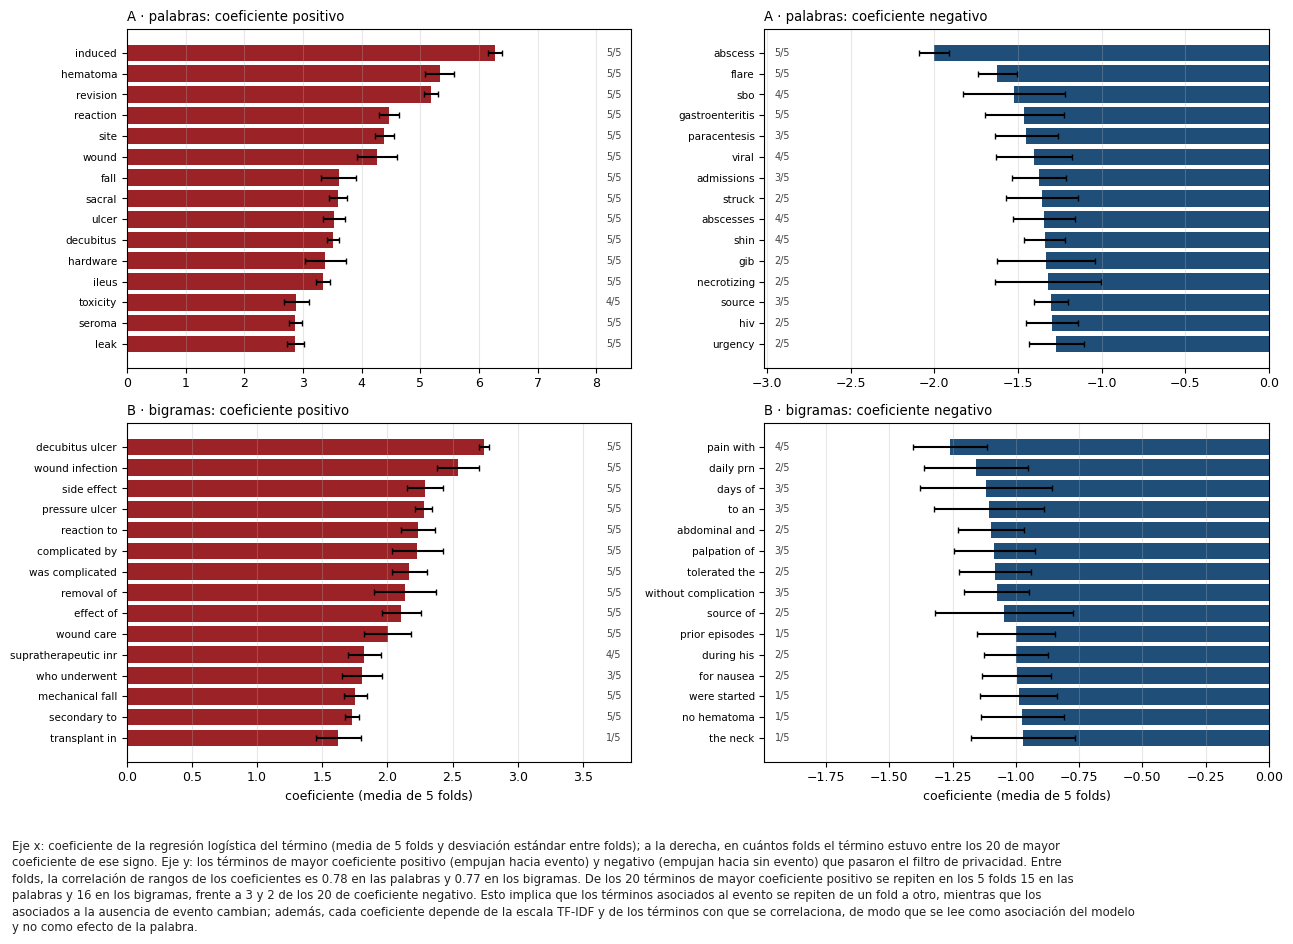

In [13]:
fig = figuras_imp.fig_terminos(R, T)
plt.show()

Fuente: elaboración propia a partir de `reportes/importancia_terminos.csv` y `reportes/importancia_resultados.json`.

En la Figura 3 se observa que los términos de coeficiente positivo con mayor peso en las palabras son *induced*, *hematoma*, *revision*, *reaction*, *site*, *wound*, y en los bigramas,
*decubitus ulcer*, *wound infection*, *side effect*, *pressure ulcer*. Los 10 términos citados estuvieron
en el *top* 20 de los 5 *folds*. Además, *fall* (caída) ocupa el puesto 7 de las palabras y *mechanical fall* el puesto
13 de los bigramas. A criterio del autor, estos términos describen
complicaciones de procedimientos, lesiones por presión, caídas y efectos adversos de medicamentos, es decir, las mismas familias de códigos
con que se construyó la etiqueta.

Por su parte, los de coeficiente negativo con mayor peso son *abscess*, *flare*, *sbo*, *gastroenteritis*, *paracentesis*, *viral* en las palabras y *pain with*, *daily prn*, *days of*, *to an* en los bigramas. A
criterio del autor, las palabras aluden a motivos de ingreso médicos, como infecciones u obstrucciones. Varias de ellas están en el *top* de
4 o 5 *folds*, pero el conjunto de términos negativos cambia de un *fold* a otro (Jaccard de 0.25
y 0.21). Esa inestabilidad del conjunto es coherente con que el modelo reconozca la ausencia
de evento por el tipo de ingreso y no por un grupo fijo de términos. Esta lectura es una interpretación y no un
hallazgo, dado que los coeficientes no miden efectos.

In [14]:
lista = pd.concat([T[(T.bloque == "A") & (T.signo == "positivo")].head(6), T[(T.bloque == "B") & (T.signo == "positivo")].head(4)])
print("De los", len(lista), "términos positivos citados en el texto, en el top de los 5 folds:", int((lista.folds_en_top == 5).sum()))
print("Puesto de fall entre las palabras positivas:", int(T[(T.bloque == "A") & (T.termino == "fall")].puesto.iloc[0]),
      "· de mechanical fall entre los bigramas positivos:", int(T[(T.bloque == "B") & (T.termino == "mechanical fall")].puesto.iloc[0]))
for (blq, signo), g in T.groupby(["bloque", "signo"], sort=False):
    print(f"{blq} · {signo}:", ", ".join(f"{r.termino} ({r.coef_media:+.2f}, top en {r.folds_en_top}/5)" for r in g.head(6).itertuples()))

De los 10 términos positivos citados en el texto, en el top de los 5 folds: 10
Puesto de fall entre las palabras positivas: 7 · de mechanical fall entre los bigramas positivos: 13
A · positivo: induced (+6.27, top en 5/5), hematoma (+5.33, top en 5/5), revision (+5.19, top en 5/5), reaction (+4.47, top en 5/5), site (+4.39, top en 5/5), wound (+4.26, top en 5/5)
A · negativo: abscess (-2.00, top en 5/5), flare (-1.62, top en 5/5), sbo (-1.52, top en 4/5), gastroenteritis (-1.46, top en 5/5), paracentesis (-1.45, top en 3/5), viral (-1.40, top en 4/5)
B · positivo: decubitus ulcer (+2.74, top en 5/5), wound infection (+2.54, top en 5/5), side effect (+2.29, top en 5/5), pressure ulcer (+2.28, top en 5/5), reaction to (+2.23, top en 5/5), complicated by (+2.23, top en 5/5)
B · negativo: pain with (-1.26, top en 4/5), daily prn (-1.16, top en 2/5), days of (-1.12, top en 3/5), to an (-1.11, top en 3/5), abdominal and (-1.10, top en 2/5), palpation of (-1.09, top en 3/5)


## 7. Tiempo de cómputo

La Tabla 7 presenta el tiempo de cada etapa, en minutos, medido por el propio *script*.

In [15]:
NOMBRE = {"modelos": "carga de la caché y ajuste de la regresión (5 folds)", "nombres_y_equivalencia": "vocabulario y control de la caché",
          "permutaciones": "permutaciones", "filtro_privacidad": "filtro de privacidad", "total": "total"}
t7 = pd.Series(R["tiempos_segundos"]).div(60).round(1).rename(NOMBRE).rename("minutos").to_frame()
t7.index.name = "Tabla 7. Etapa"
t7

,minutos
Tabla 7. Etapa,
carga de la caché y ajuste de la regresión (5 folds),5.6
vocabulario y control de la caché,10.8
permutaciones,0.2
filtro de privacidad,3.5
total,20.3


Fuente: elaboración propia a partir de `reportes/importancia_resultados.json`.

Como se aprecia en la Tabla 7, el cálculo completo tomó 20.3 minutos, de modo que no fue
necesario reducir las 30 permutaciones. La mayor parte del tiempo se destinó a reconstruir el vocabulario de cada *fold* y
a comprobar la caché (10.8 minutos), mientras que las permutaciones tomaron
0.2 minutos, porque se calculan sobre el aporte de cada grupo al *logit*.

## 8. Conclusiones y siguiente paso

Una vez analizados los resultados, se concluye que el modelo vigente se apoya sobre todo en el texto de la epicrisis. La permutación conjunta
de palabras y bigramas reduce la PR-AUC en 0.2349, frente a 0.1106 del contexto, y el orden de los bloques se repite en
los 5 *folds*. Dentro del contexto pesan sobre todo estancia (días) y servicio al ingreso, y los términos que empujan
hacia evento son estables entre *folds*, a diferencia de los que empujan hacia sin evento.

Es preciso tomar en consideración que estas importancias describen el comportamiento del modelo entrenado y no relaciones causales, y que la
permutación de cada bloque por separado puede subestimar su peso si los bloques comparten información. Asimismo, ninguna cifra de este cuaderno usó la partición de
*test* ni se calculó por servicio, edad o largo de la nota, de modo que HE1 queda intacta para su evaluación.

Se recomienda, como siguiente paso del Sprint 3, evaluar HE1 con la comparación por servicio, grupo de edad y decil de largo prevista desde la
semana 5, y recalibrar las probabilidades a la prevalencia real. Para reproducir este análisis se ejecuta `python src/importancia_variables.py`,
el cual requiere la caché de conteos de `python src/experimentos_hp.py --solo-conteos`.